In [1]:
import os, sys, glob, io, contextlib, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging
logging.getLogger('harmonypy').setLevel(logging.ERROR)
logging.getLogger('harmonypy').propagate=False
logging.getLogger('harmonypy').disabled=True

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
# load manifold; report module gene recovery
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print('cells:', adata.shape[0])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 1061
Gast: 73/81 genes present
pSom: 86/98 genes present
Crest: 100/104 genes present


In [4]:
# GATE 2: module geography. Low-Gast melanoma -> Crest-dominant terminal readout.
print('raw module means (LOW Gast; Crest-dominant melanoma):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
for m,lab_ in [('Gast_sm','Gastrulation'),('pSom_sm','Somitogenesis'),('Crest_sm','Neural-crest')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
# overlap (hub) vs inverse-gradient test (Gast/pSom co-express? Crest inverse?)
def enrich(x,y):
    xz=(adata.obs[x]-adata.obs[x].mean())/adata.obs[x].std()
    yz=(adata.obs[y]-adata.obs[y].mean())/adata.obs[y].std()
    joint=((xz>0.5)&(yz>0.5)).mean(); exp=(xz>0.5).mean()*(yz>0.5).mean()
    return joint/exp if exp>0 else np.nan
print(f'joint Gast&pSom-high enrichment = {enrich("Gast","pSom"):.2f} (>1 = overlap, not competing arms)')
print(f'joint pSom&Crest-high enrichment = {enrich("pSom","Crest"):.2f} (<1 = inverse gradient, not a hub)')
print(f'joint Gast&Crest-high enrichment = {enrich("Gast","Crest"):.2f}')
print('GATE 2 = GO (non-branching): Gast/pSom overlap at the origin, Crest an inverse terminal gradient;')
print('  Crest peaks at the terminus (not a Gast arm) -> no inversion flag. GATE 3 = NA (no bifurcation).')

raw module means (LOW Gast; Crest-dominant melanoma): {'Gast': -0.5067, 'pSom': -0.0681, 'Crest': 0.1493}
smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.97
  Crest_sm vs Gast_sm: r = -0.93
  Crest_sm vs pSom_sm: r = -0.94
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.975
  pSom_sm: rho = -0.979
  Crest_sm: rho = +0.938
Gastrulation-high decile mean pseudotime = 0.00
Somitogenesis-high decile mean pseudotime = 0.00
Neural-crest-high decile mean pseudotime = 0.98
joint Gast&pSom-high enrichment = 1.37 (>1 = overlap, not competing arms)
joint pSom&Crest-high enrichment = 0.23 (<1 = inverse gradient, not a hub)
joint Gast&Crest-high enrichment = 0.16
GATE 2 = GO (non-branching): Gast/pSom overlap at the origin, Crest an inverse terminal gradient;
  Crest peaks at the terminus (not a Gast arm) -> no inversion flag. GATE 3 = NA (no bifurcation).


saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


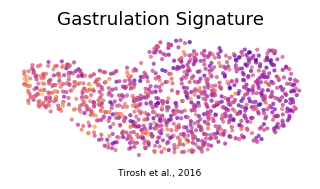

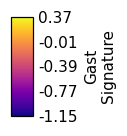

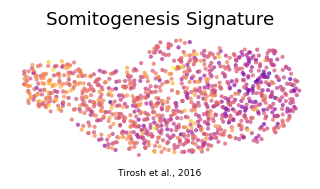

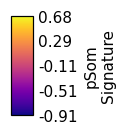

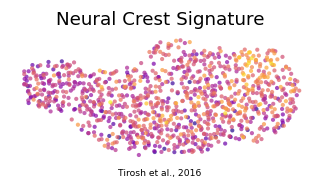

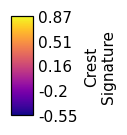

In [5]:
# signature UMAPs on the house linear layout + external colorbars (reference style; RAW scores shown)
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Tirosh et al., 2016', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show()
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (1061, 19950)
